In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

date_columns = ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

print(listings.shape)

(4574, 73)


## Part 2: Go deeper

In [76]:
listings["has_reviews"].value_counts()

has_reviews
True     3930
False     644
Name: count, dtype: int64

In [77]:
only_has_reviews = listings[listings["has_reviews"]]

only_has_reviews["has_reviews"].value_counts()

has_reviews
True    3930
Name: count, dtype: int64

### 1.

- The spread of ratings seem to tighten with more reviews, with that effect being more pronounced under 50 reviews
- At very few reviews we have a wide spread with both endpoints represented (1 to 5)
- As we come to 50 reviews the spread has tightened to about 4.2 to 5 with very few outliers after that point
- Over all the spread seems to tighten all the way to the limit at 300 reviews where the spread is between about 4.6 and 5
****
- The limit of 'number_of_reviews' from 0 to 300 excludes 91 values and does not affect the general shape of the plot.
****
- The plot tells us that if the number of reviews are a few, low value reviews probably has a bigger effect on review_scores_rating. And probably because a really low score can move the average a lot if there are not that many reviews.
- This effect wouldnt be that dramatic if the average review-scores where not so heavily leaning towards the top of the spectrum (5).

In [78]:
excluded = only_has_reviews["number_of_reviews"] > 300

print(only_has_reviews[excluded].shape[0])

91


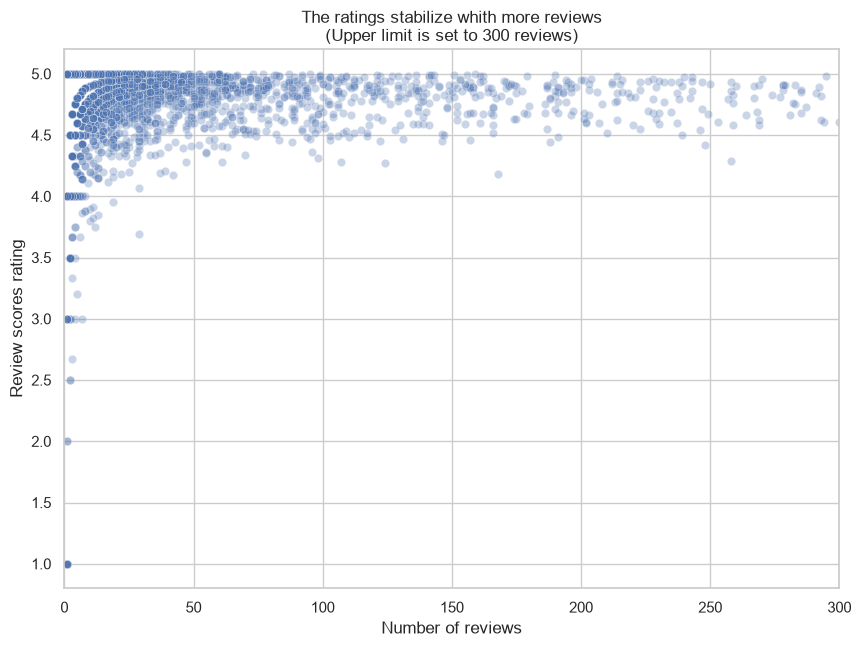

In [79]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=only_has_reviews, x="number_of_reviews", y="review_scores_rating", alpha=0.3, ax=ax)

ax.set_xlim(0, 300)
ax.set_title("The ratings stabilize whith more reviews\n(Upper limit is set to 300 reviews)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Review scores rating")

plt.show()

### 2.

- We can say that the superhosts on average have more reviews, but we do not know what the cause is.

In [96]:
listings["host_is_superhost"].value_counts()

host_is_superhost
False    3837
True      737
Name: count, dtype: int64

In [103]:
excluded = listings["number_of_reviews"] > 300

print(listings[excluded].shape[0])

91


In [111]:
excluded_super = ((listings["number_of_reviews"] > 300)
                  & (listings["host_is_superhost"]))

excluded_not_super = ((listings["number_of_reviews"] > 300)
                  & (~listings["host_is_superhost"]))

print(listings[excluded_super].shape[0])
print(listings[excluded_not_super].shape[0])

47
44


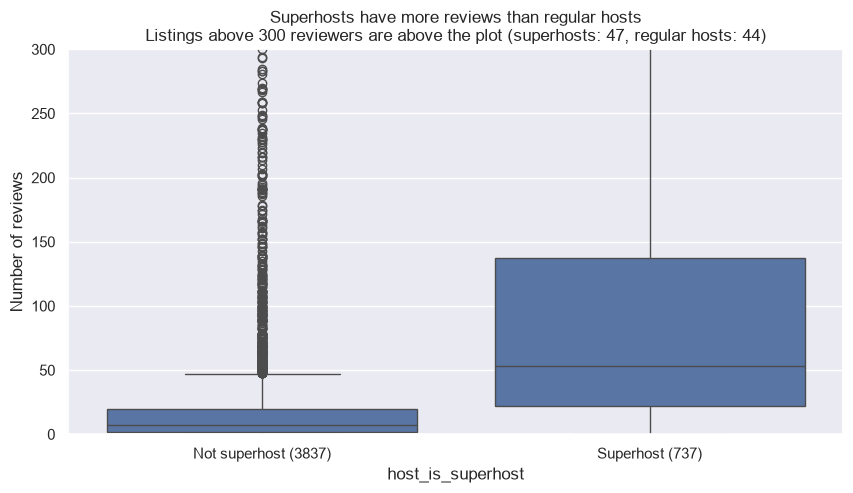

In [120]:
sns.set_theme(style="darkgrid")

is_superhost = listings[listings["host_is_superhost"].isin([True, False])]

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(data=is_superhost, x="host_is_superhost", y="number_of_reviews", ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f"Superhosts have more reviews than regular hosts\nListings above 300 reviewers are above the plot (superhosts: {listings[excluded_super].shape[0]}, regular hosts: {listings[excluded_not_super].shape[0]})")
ax.set_ylabel("Number of reviews")
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Not superhost ({(is_superhost["host_is_superhost"] == False).sum()})", 
    f"Superhost ({(is_superhost["host_is_superhost"] == True).sum()})"])

plt.show()